# Import Library

In [ ]:
# Library yang sering digunakan
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm as tq

In [ ]:
# Libraries untuk pemrosesan data gambar
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [ ]:
# Libraries untuk pembangunan model
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import GlobalAveragePooling2D, InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization, Input
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2, EfficientNetB4, EfficientNetB0, ResNet50, EfficientNetB1, EfficientNetB2, EfficientNetB3, EfficientNetB4
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [ ]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
print(tf.__version__)

2.19.0


# Load Dataset

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"nabilasyalwani","key":"8c19bdab005ef2c18f7a9ba31d1a59d5"}'}

In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download sovitrath/diabetic-retinopathy-224x224-2019-data

Dataset URL: https://www.kaggle.com/datasets/sovitrath/diabetic-retinopathy-224x224-2019-data
License(s): CC0-1.0
 75% 178M/238M [00:00<00:00, 1.86GB/s]
100% 238M/238M [00:00<00:00, 1.21GB/s]


In [ ]:
!unzip /content/diabetic-retinopathy-224x224-2019-data.zip

Archive:  /content/diabetic-retinopathy-224x224-2019-data.zip
  inflating: colored_images/Mild/0024cdab0c1e.png  
  inflating: colored_images/Mild/00cb6555d108.png  
  inflating: colored_images/Mild/0124dffecf29.png  
  inflating: colored_images/Mild/01b3aed3ed4c.png  
  inflating: colored_images/Mild/0369f3efe69b.png  
  inflating: colored_images/Mild/03e25101e8e8.png  
  inflating: colored_images/Mild/04ac765f91a1.png  
  inflating: colored_images/Mild/059bc89df7f4.png  
  inflating: colored_images/Mild/05a5183c92d0.png  
  inflating: colored_images/Mild/0684311afdfc.png  
  inflating: colored_images/Mild/06b71823f9cd.png  
  inflating: colored_images/Mild/07929d32b5b3.png  
  inflating: colored_images/Mild/07a1c7073982.png  
  inflating: colored_images/Mild/086d41d17da8.png  
  inflating: colored_images/Mild/09935d72892b.png  
  inflating: colored_images/Mild/0a3202889f4d.png  
  inflating: colored_images/Mild/0a61bddab956.png  
  inflating: colored_images/Mild/0ad7f631dedb.png  
  

In [ ]:
!unzip /content/dataset_rs_undaan.zip

Archive:  /content/dataset_rs_undaan.zip
   creating: dataset_rs_undaan/
   creating: dataset_rs_undaan/dataset_rs_undaan/
   creating: dataset_rs_undaan/dataset_rs_undaan/Mild/
  inflating: dataset_rs_undaan/dataset_rs_undaan/Mild/51od.png  
  inflating: dataset_rs_undaan/dataset_rs_undaan/Mild/51os.png  
   creating: dataset_rs_undaan/dataset_rs_undaan/Moderate/
  inflating: dataset_rs_undaan/dataset_rs_undaan/Moderate/122os.png  
  inflating: dataset_rs_undaan/dataset_rs_undaan/Moderate/160od.png  
  inflating: dataset_rs_undaan/dataset_rs_undaan/Moderate/160os.png  
  inflating: dataset_rs_undaan/dataset_rs_undaan/Moderate/73od.png  
   creating: dataset_rs_undaan/dataset_rs_undaan/No_DR/
  inflating: dataset_rs_undaan/dataset_rs_undaan/No_DR/1.png  
  inflating: dataset_rs_undaan/dataset_rs_undaan/No_DR/2.png  
  inflating: dataset_rs_undaan/dataset_rs_undaan/No_DR/3.png  
  inflating: dataset_rs_undaan/dataset_rs_undaan/No_DR/4.png  
  inflating: dataset_rs_undaan/dataset_rs_unda

In [ ]:
!mv /content/dataset_rs_undaan/dataset_rs_undaan/* /content/dataset_rs_undaan

In [ ]:
!rm -rf /content/dataset_rs_undaan/dataset_rs_undaan

In [ ]:
# Direktori awal untuk train dan test
# dataset_dir = "colored_images"
dataset_dir = "dataset_rs_undaan"

# Direktori baru untuk dataset gabungan
combined_dir = "dataset"

In [ ]:
os.makedirs(combined_dir, exist_ok=True)

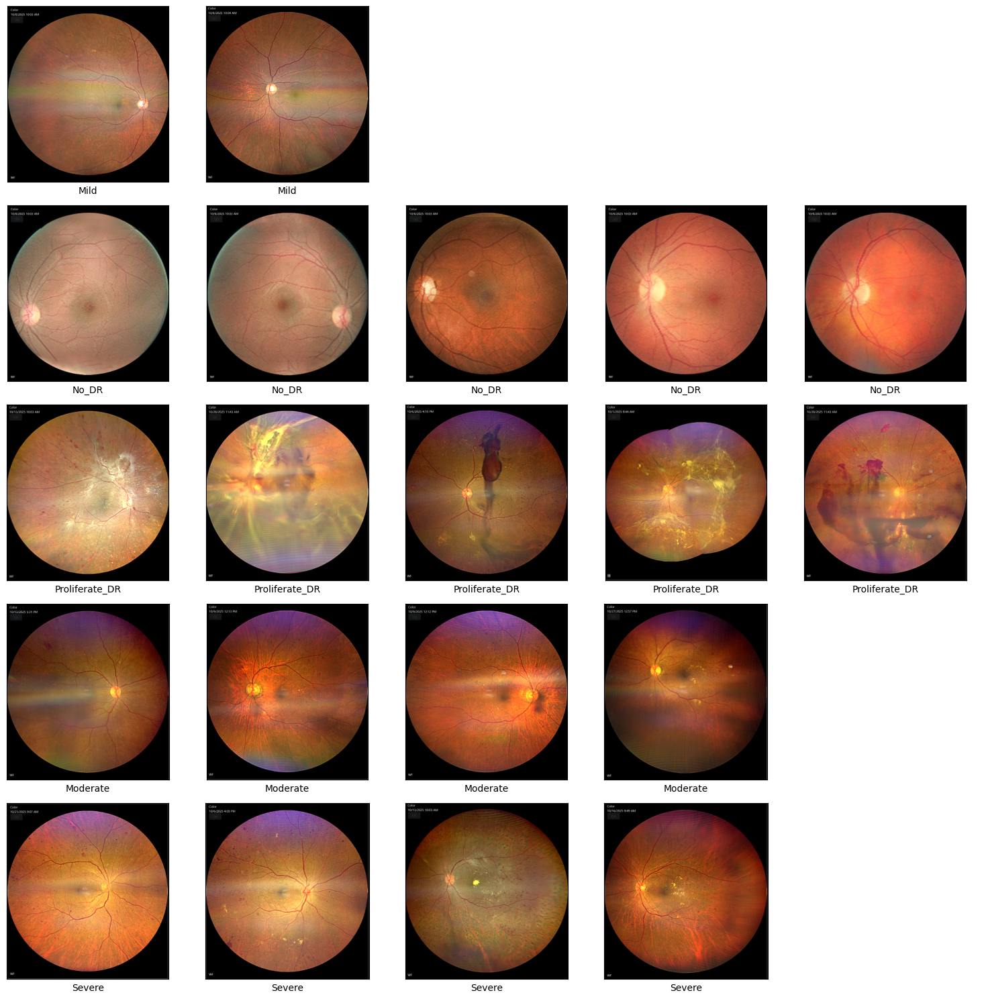

In [ ]:
fundus_image = {}
path = ""
path_sub = os.path.join(path, "dataset_rs_undaan")

for i in os.listdir(path_sub):
  fundus_image[i] = os.listdir(os.path.join(path_sub, i))

fig, axs = plt.subplots(len(fundus_image.keys()), 5, figsize=(15, 15))

for i, class_name in enumerate(os.listdir(path_sub)):
    num_images_to_sample = min(5, len(fundus_image[class_name]))
    images = np.random.choice(fundus_image[class_name], num_images_to_sample, replace=False)

    for j, image_name in enumerate(images):
        img_path = os.path.join(path_sub,class_name, image_name)
        img = Image.open(img_path)
        axs[i, j].imshow(img)
        axs[i, j].set(xlabel=class_name, xticks=[], yticks=[])

    # Hide unused subplots if fewer than 5 images are displayed
    for j_extra in range(num_images_to_sample, 5):
        axs[i, j_extra].axis('off')

fig.tight_layout()
plt.show()

# Pre-Processing

In [ ]:
# Preprocessing Function
def preprocess(img, show_steps=False):
    img_np = np.array(img)

    # 1) Image cropping
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    ret, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_crop = cv2.boundingRect(contours[0])

    if len(contours) > 0:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        img_cropped = img.crop((x, y, x + w, y + h))
    else:
        img_cropped = img
    img_cropped = img_cropped.convert('RGB')

    # 2) Image denoising
    img_cropped_np = np.array(img_cropped)
    img_denoised_np = cv2.GaussianBlur(img_cropped_np, (3, 3), 0)

    # 3) Histogram equalization (HE)
    lab = cv2.cvtColor(img_denoised_np, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    clahe_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    # 4) Image resizing
    resize_img = Image.fromarray(clahe_img)
    resize_img = resize_img.resize((224, 224))

    # # 5) Normalization
    # img_np = np.array(resize_img).astype('float32') / 255.0
    # mean = [0.485, 0.456, 0.406]
    # std = [0.229, 0.224, 0.225]
    # img_np = (img_np - mean) / std

    if show_steps:
        fig, axes = plt.subplots(1, 5, figsize=(20, 5))
        axes[0].imshow(img)
        axes[0].set_title('Original')
        axes[0].axis('off')

        axes[1].imshow(img_cropped)
        axes[1].set_title('Cropped')
        axes[1].axis('off')

        axes[2].imshow(img_denoised_np)
        axes[2].set_title('Denoised')
        axes[2].axis('off')

        axes[3].imshow(clahe_img)
        axes[3].set_title('CLAHE)')
        axes[3].axis('off')

        axes[4].imshow(resize_img)
        axes[4].set_title('Resized')
        axes[4].axis('off')

        plt.tight_layout()
        plt.show()

    # return resize_img
    return resize_img

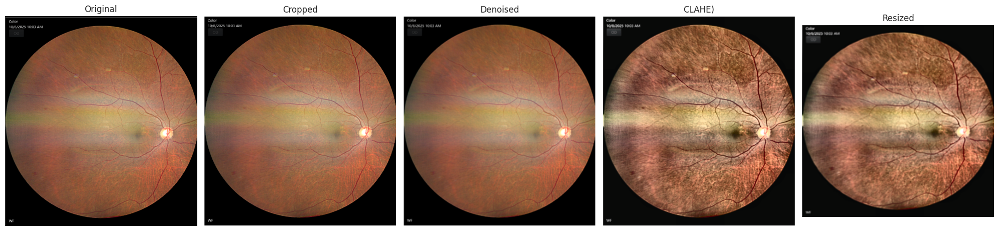

In [ ]:
img = Image.open("/content/dataset_rs_undaan/Mild/51od.png").convert("RGB")
contoh_preprocess_img = preprocess(img, True)

In [ ]:
for category in os.listdir(dataset_dir):
  category_dir = os.path.join(dataset_dir, category)
  if os.path.isdir(category_dir):
    target_dir = os.path.join(combined_dir, category)
    os.makedirs(target_dir, exist_ok=True)
    for img_name in os.listdir(category_dir):
        src_img = os.path.join(category_dir, img_name)
        dst_img = os.path.join(target_dir, img_name)
        img = Image.open(src_img).convert("RGB")
        img = preprocess(img)
        img.save(dst_img)

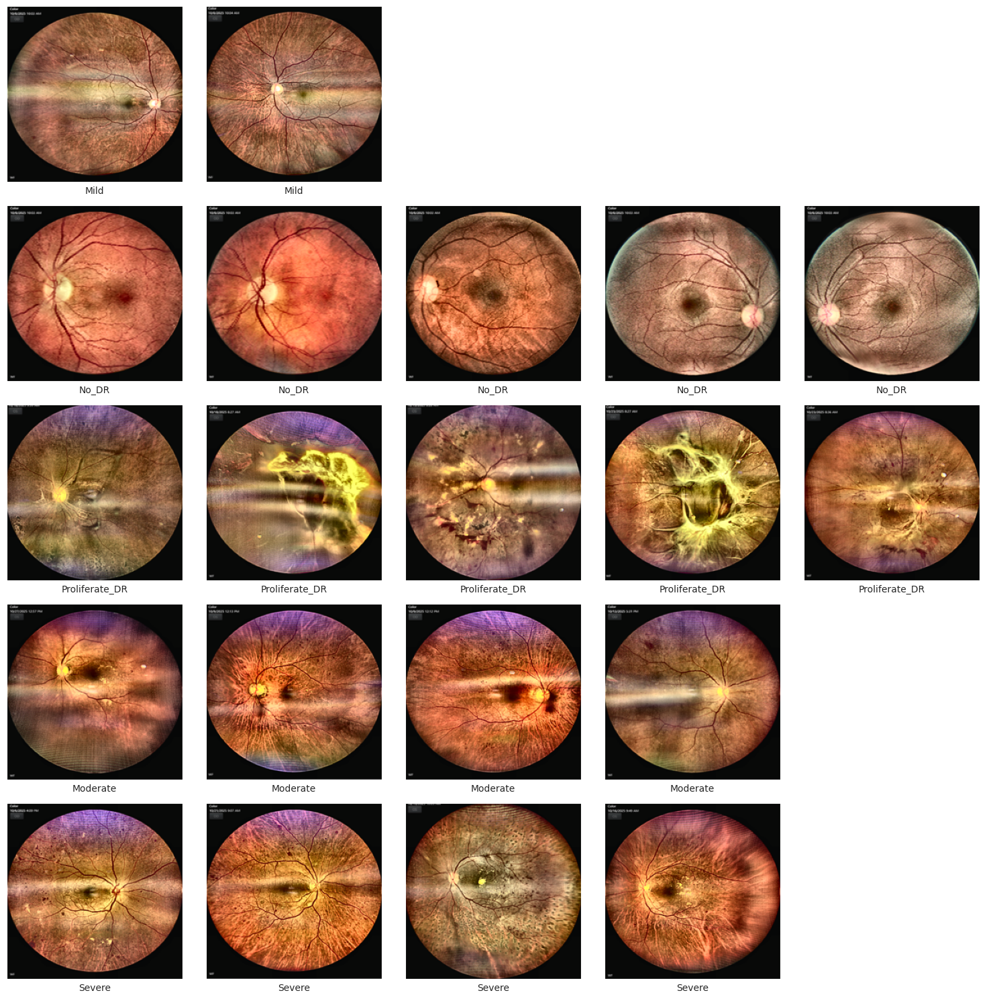

In [ ]:
fundus_image = {}
path = ""
path_sub = os.path.join(path, combined_dir)

for i in os.listdir(path_sub):
  fundus_image[i] = os.listdir(os.path.join(path_sub, i))

fig, axs = plt.subplots(len(fundus_image.keys()), 5, figsize=(15, 15))

for i, class_name in enumerate(os.listdir(path_sub)):
    num_images_to_sample = min(5, len(fundus_image[class_name]))
    images = np.random.choice(fundus_image[class_name], num_images_to_sample, replace=False)

    for j, image_name in enumerate(images):
        img_path = os.path.join(path_sub,class_name, image_name)
        img = Image.open(img_path)
        axs[i, j].imshow(img)
        axs[i, j].set(xlabel=class_name, xticks=[], yticks=[])

    # Hide unused subplots if fewer than 5 images are displayed
    for j_extra in range(num_images_to_sample, 5):
        axs[i, j_extra].axis('off')

fig.tight_layout()
plt.show()

In [ ]:
check_picture = "/content/dataset/Moderate/160od.png"
img = Image.open(check_picture)
print(img.mode)

RGB


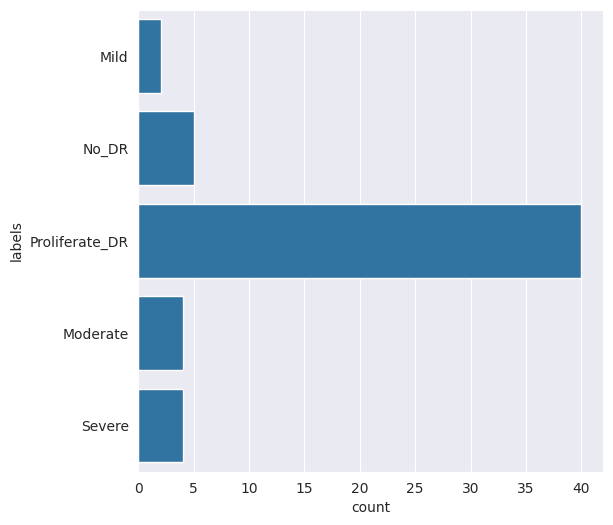

In [ ]:
fundus_path = "dataset/"

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(fundus_path):
  for name in files:
    full_path.append(os.path.join(path, name))
    labels.append(path.split('/')[-1])
    file_name.append(name)

distribution_train = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_train['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [ ]:
mypath= 'dataset/'

file_name = []
labels = []
full_path = []
for path, subdirs, files in os.walk(mypath):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

df = pd.DataFrame({"path":full_path,'file_name':file_name,"labels":labels})
# Melihat jumlah data gambar pada masing-masing label
df.groupby(['labels']).size()

,0
labels,
Mild,2
Moderate,4
No_DR,5
Proliferate_DR,40
Severe,4


In [ ]:
# Resize helper
def resize_img(img, size=(224,224)):
    return cv2.resize(img, size)

# CLAHE preprocessing
def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

# Rotasi berlawanan arah jarum jam
def anticlockwise_rotation(img):
    img = resize_img(img)
    sudut = random.randint(0,180)
    return rotate(img, sudut, preserve_range=True).astype(np.uint8)

# Rotasi searah jarum jam
def clockwise_rotation(img):
    img = resize_img(img)
    sudut = random.randint(0,180)
    return rotate(img, -sudut, preserve_range=True).astype(np.uint8)

# Flip vertical
def flip_up_down(img):
    img = resize_img(img)
    return np.flipud(img)

# Brightness
def add_brightness(img):
    img = resize_img(img)
    return adjust_gamma(img, gamma=0.5, gain=1)

# Blur
def blur_image(img):
    img = resize_img(img)
    return cv2.GaussianBlur(img, (9,9), 0)

# Shear
def sheared(img):
    img = resize_img(img)
    transform = AffineTransform(shear=0.2)
    shear_image = warp(img, transform, mode="wrap", preserve_range=True)
    return shear_image.astype(np.uint8)

# Warp shift (geser translasi)
def warp_shift(img):
    img = resize_img(img)
    transform = AffineTransform(translation=(0,40))
    warp_image = warp(img, transform, mode="wrap", preserve_range=True)
    return warp_image.astype(np.uint8)

# Augmentations
def rotate_image(img):
    angle = random.choice([0, 90, 180, 270])
    return rotate(img, angle, preserve_range=True).astype(np.uint8)

def flip_horizontal(img):
    return cv2.flip(img, 1)

def flip_vertical(img):
    return cv2.flip(img, 0)

def adjust_brightness(img):
    factor = random.uniform(0.8, 1.2)
    return np.clip(img * factor, 0, 255).astype(np.uint8)

def adjust_contrast(img):
    factor = random.uniform(0.8, 1.2)
    mean = np.mean(img, axis=(0,1), keepdims=True)
    img = (img - mean) * factor + mean
    return np.clip(img, 0, 255).astype(np.uint8)

def adjust_color(img):
    factor = random.uniform(0.8, 1.2)
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 1] *= factor
    hsv[..., 1] = np.clip(hsv[..., 1], 0, 255)
    img_colored = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    return img_colored

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np
# from PIL import Image

# # Pastikan contoh_preprocess_img adalah PIL.Image
# img = Image.open("/content/colored_images/Proliferate_DR/001639a390f0.png").convert("RGB")
# contoh_preprocess_img = preprocess(img)

# # Ubah ke NumPy array agar bisa diproses oleh OpenCV
# original_image = np.array(contoh_preprocess_img)

# # Resize
# original_image = resize_img(original_image)

# # Transformasi
# transformations = {
#     'rotate image': rotate_image,
#     'flip horizontal': flip_horizontal,
#     'flip vertical': flip_vertical,
#     'adjust brightness': adjust_brightness,
#     'adjust contrast': adjust_contrast,
#     'adjust color': adjust_color,
# }

# # Buat figure 2 baris, 3 kolom
# rows, cols = 2, int(len(transformations)/2)
# fig, axs = plt.subplots(rows, cols, figsize=(15, 8))

# # Flatten agar bisa diiterasi dengan mudah
# axs = axs.flatten()

# # Tampilkan tiap transformasi
# for ax, (name, func) in zip(axs, transformations.items()):
#     transformed_image = func(original_image)
#     img_transformed = Image.fromarray(transformed_image.astype('uint8'))
#     ax.imshow(img_transformed)
#     ax.set_title(name, fontsize=10)
#     ax.axis('off')

# plt.tight_layout()
# plt.show()

In [ ]:
# Membuat variabel transformasi yang akan menyimpan semua proses pra-pemrosesan yang telah dilakukan sebelumnya
transformations = { 'rotate image': rotate_image,
                    'flip horizontal': flip_horizontal,
                    'flip vertical': flip_vertical,
                    'adjust brightness': adjust_brightness,
                    'adjust contrast': adjust_contrast,
                    'adjust color': adjust_color,
                  }

subfolders = ["mild",  "moderate", "normal", "severe"]
images_to_generate = [8, 6, 5, 6]   # jumlah augmentasi per kelas

base_path = "dataset"

for subfolder, gen_count in zip(subfolders, images_to_generate):
    images_path = os.path.join(base_path, subfolder)
    images = [os.path.join(images_path, im) for im in os.listdir(images_path)]

    i = 1
    while i <= gen_count:
        image = random.choice(images)
        try:
            original_image = io.imread(image)

            if original_image.ndim == 2:  # grayscale
                original_image = cv2.cvtColor(original_image, cv2.COLOR_GRAY2RGB)

            original_image = resize_img(original_image)

            transformed_image = original_image.copy()
            transformation_count = random.randint(1,2)

            for _ in range(transformation_count):
                key = random.choice(list(transformations))
                transformed_image = transformations[key](transformed_image)

            new_image_path = f"{images_path}/augmented_{subfolder}_{i}.jpg"
            transformed_image = img_as_ubyte(transformed_image)
            cv2.imwrite(new_image_path, cv2.cvtColor(transformed_image, cv2.COLOR_RGB2BGR))
            i += 1

        except ValueError as e:
            print('Could not read', image, ':', e, 'skipping.')


FileNotFoundError: [Errno 2] No such file or directory: 'dataset/mild'

In [ ]:
fundus_path = "dataset/"

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(fundus_path):
  for name in files:
    full_path.append(os.path.join(path, name))
    labels.append(path.split('/')[-1])
    file_name.append(name)

distribution_train = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_train['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

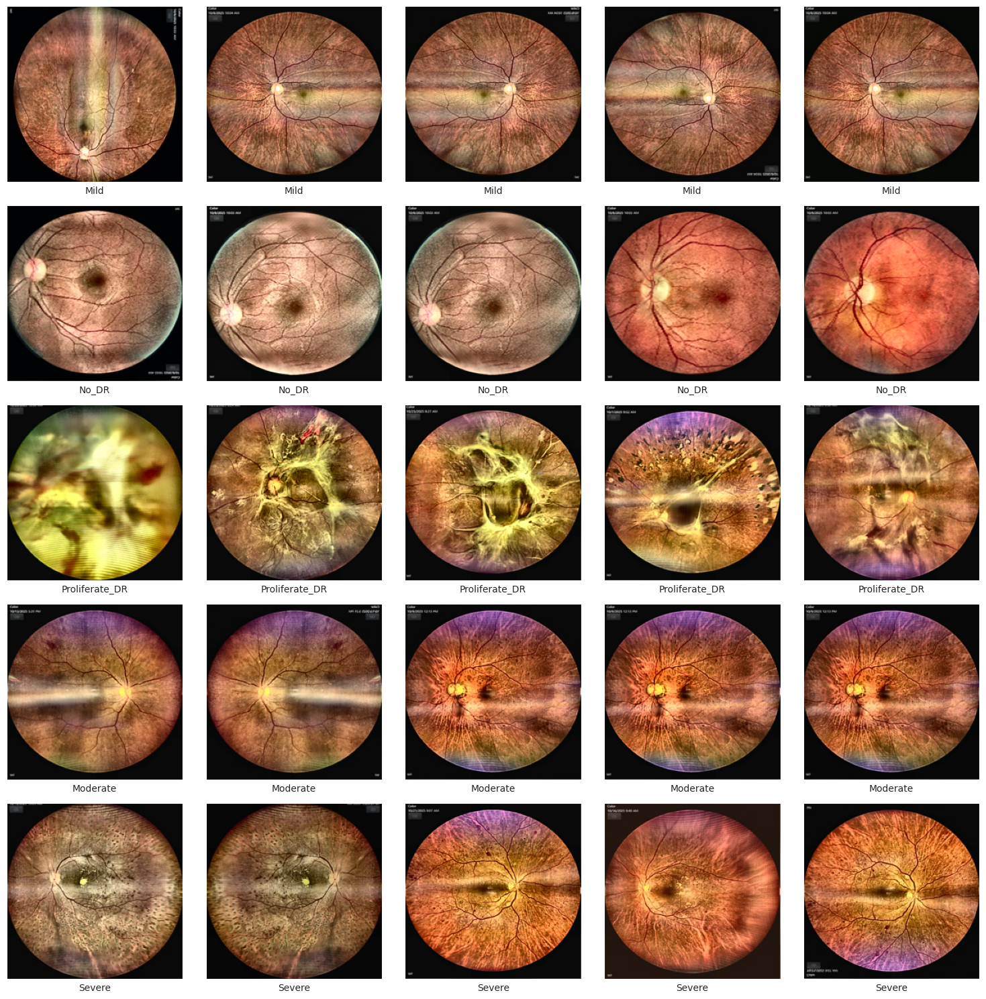

In [ ]:
fundus_image = {}
path = ""
path_sub = os.path.join(path, combined_dir)

for i in os.listdir(path_sub):
  fundus_image[i] = os.listdir(os.path.join(path_sub, i))

fig, axs = plt.subplots(len(fundus_image.keys()), 5, figsize=(15, 15))

for i, class_name in enumerate(os.listdir(path_sub)):
    num_images_to_sample = min(5, len(fundus_image[class_name]))
    images = np.random.choice(fundus_image[class_name], num_images_to_sample, replace=False)

    for j, image_name in enumerate(images):
        img_path = os.path.join(path_sub,class_name, image_name)
        img = Image.open(img_path)
        axs[i, j].imshow(img)
        axs[i, j].set(xlabel=class_name, xticks=[], yticks=[])

    # Hide unused subplots if fewer than 5 images are displayed
    for j_extra in range(num_images_to_sample, 5):
        axs[i, j_extra].axis('off')

fig.tight_layout()
plt.show()

In [ ]:
mypath= 'dataset/'

file_name = []
labels = []
full_path = []
for path, subdirs, files in os.walk(mypath):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

df = pd.DataFrame({"path":full_path,'file_name':file_name,"labels":labels})
# Melihat jumlah data gambar pada masing-masing label
df.groupby(['labels']).size()

,0
labels,
Mild,10
Moderate,10
No_DR,10
Proliferate_DR,40
Severe,10


In [ ]:
df

,path,file_name,labels
0,dataset/Mild/augmented_Mild_2.jpg,augmented_Mild_2.jpg,Mild
1,dataset/Mild/augmented_Mild_5.jpg,augmented_Mild_5.jpg,Mild
2,dataset/Mild/augmented_Mild_4.jpg,augmented_Mild_4.jpg,Mild
3,dataset/Mild/augmented_Mild_8.jpg,augmented_Mild_8.jpg,Mild
4,dataset/Mild/augmented_Mild_6.jpg,augmented_Mild_6.jpg,Mild
...,...,...,...
75,dataset/Severe/151od.png,151od.png,Severe
76,dataset/Severe/augmented_Severe_1.jpg,augmented_Severe_1.jpg,Severe
77,dataset/Severe/augmented_Severe_4.jpg,augmented_Severe_4.jpg,Severe
78,dataset/Severe/61od.png,61od.png,Severe


In [ ]:
X= df['path']
y= df['labels']

# Split dataset awal menjadi data train dan test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=300)

In [ ]:
# Menyatukan ke dalam masing-masing dataframe
df_tr = pd.DataFrame({'path':X_train,'labels':y_train,'set':'train'})
df_te = pd.DataFrame({'path':X_test,'labels':y_test,'set':'test'})

In [ ]:
# Gabungkan DataFrame df_tr dan df_te
df_all = pd.concat([df_tr, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')
print(df_all.sample(5))

datasource_path = "dataset/"
dataset_path = "Dataset-Final/"


set    labels        
test   Mild               1
       Moderate           3
       No_DR              2
       Proliferate_DR     7
       Severe             3
train  Mild               9
       Moderate           7
       No_DR              8
       Proliferate_DR    33
       Severe             7
dtype: int64 


                                   path          labels    set
60      dataset/Proliferate_DR/65os.png  Proliferate_DR  train
48      dataset/Proliferate_DR/49os.png  Proliferate_DR  train
14    dataset/Mild/augmented_Mild_7.jpg            Mild  train
5       dataset/Proliferate_DR/76os.png  Proliferate_DR  train
2   dataset/No_DR/augmented_No_DR_4.jpg           No_DR  train


In [ ]:
for index, row in tq(df_all.iterrows()):
    file_path = row['path']
    if os.path.exists(file_path) == False:
            file_path = os.path.join(datasource_path,row['labels'],row['image'].split('.')[0])

    if os.path.exists(os.path.join(dataset_path,row['set'],row['labels'])) == False:
        os.makedirs(os.path.join(dataset_path,row['set'],row['labels']))

    destination_file_name = file_path.split('/')[-1]
    file_dest = os.path.join(dataset_path,row['set'],row['labels'],destination_file_name)

    if os.path.exists(file_dest) == False:
        shutil.copy2(file_path,file_dest)

0it [00:00, ?it/s]

In [ ]:
# Definisikan direktori training dan test
TRAIN_DIR = "Dataset-Final/train/"
TEST_DIR = "Dataset-Final/test/"

train_mild = os.path.join(TRAIN_DIR + '/mild')
train_moderate = os.path.join(TRAIN_DIR + '/moderate')
train_normal = os.path.join(TRAIN_DIR + '/normal')
train_pdr = os.path.join(TRAIN_DIR + '/pdr')
train_severe = os.path.join(TRAIN_DIR + '/severe')
test_mild = os.path.join(TEST_DIR + '/mild')
test_moderate = os.path.join(TEST_DIR + '/moderate')
test_normal = os.path.join(TEST_DIR + '/normal')
test_pdr = os.path.join(TEST_DIR + '/pdr')
test_severe = os.path.join(TEST_DIR + '/severe')

print("Total number of mild images in training set: ",len(os.listdir(train_mild)))
print("Total number of moderate images in training set: ",len(os.listdir(train_moderate)))
print("Total number of normal images in training set: ",len(os.listdir(train_normal)))
print("Total number of pdr images in training set: ",len(os.listdir(train_pdr)))
print("Total number of severe images in training set: ",len(os.listdir(train_severe)))

print("Total number of mild images in test set: ",len(os.listdir(test_mild)))
print("Total number of moderate images in test set: ",len(os.listdir(test_moderate)))
print("Total number of normal images in test set: ",len(os.listdir(test_normal)))
print("Total number of pdr images in test set: ",len(os.listdir(test_pdr)))
print("Total number of severe images in test set: ",len(os.listdir(test_severe)))


FileNotFoundError: [Errno 2] No such file or directory: 'Dataset-Final/train//mild'

# Training Model

In [ ]:
# from tensorflow.keras.applications.efficientnet import preprocess_input
# from tensorflow.keras.applications.resnet50 import preprocess_input, ResNet50
# from tensorflow.keras.applications.densenet import preprocess_input
# from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
# from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.applications.vgg19 import VGG19, preprocess_input


# Buat objek ImageDataGenerator yang menormalkan gambar
datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                              rotation_range=15,
                              zoom_range=0.1,
                              width_shift_range=0.1,
                              height_shift_range=0.1,
                              horizontal_flip=True,
                              validation_split=0.2)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                                  rotation_range=15,
                                  zoom_range=0.1,
                                  width_shift_range=0.1,
                                  height_shift_range=0.1,
                                  horizontal_flip=True)

train_generator = datagen.flow_from_directory(
    TRAIN_DIR,
    batch_size=16,
    target_size=(224,224),
    color_mode="rgb",
    class_mode='categorical',
    subset='training',
    shuffle=True)

validation_generator = datagen.flow_from_directory(
    TRAIN_DIR,
    batch_size=16,
    target_size=(224,224),
    color_mode="rgb",
    class_mode='categorical',
    subset='validation',
    shuffle=False)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    batch_size=1,
    target_size=(224,224),
    color_mode="rgb",
    class_mode='categorical',
    shuffle=False)

Found 62 images belonging to 5 classes.
Found 11 images belonging to 5 classes.
Found 25 images belonging to 5 classes.


In [ ]:
print(train_generator.class_indices)
print(train_generator.classes)
np.bincount(train_generator.classes)

{'mild': 0, 'moderate': 1, 'normal': 2, 'pdr': 3, 'severe': 4}
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4]


array([ 8,  8,  8, 31,  7])

In [ ]:
from tensorflow.keras.regularizers import l2

input_tensor = Input(shape=(224,224,3))
base_model = VGG19(include_top=False, weights='imagenet', input_tensor=input_tensor)
base_model.trainable = False

# Custom classification head
x = base_model.output
x = BatchNormalization()(x)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
output_tensor = Dense(5, activation='softmax')(x)  # multi-class classification

# Final model
model_1 = Model(inputs=input_tensor, outputs=output_tensor)

# Compile model
model_1.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Summary
model_1.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │             

 Total params: 20,100,677 (76.68 MB)

 Trainable params: 75,269 (294.02 KB)

 Non-trainable params: 20,025,408 (76.39 MB)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

labels = train_generator.classes
class_weights = compute_class_weight(class_weight='balanced',
                                     classes=np.unique(labels),
                                     y=labels)
class_weight = dict(enumerate(class_weights))

In [ ]:
print(train_generator.samples)
print(train_generator.class_indices)

62
{'mild': 0, 'moderate': 1, 'normal': 2, 'pdr': 3, 'severe': 4}


In [ ]:
history = model_1.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator,
    class_weight=class_weight,
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 59s 15s/step - accuracy: 0.3221 - loss: 1.5942 - val_accuracy: 0.0909 - val_loss: 2.7745
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 54s 13s/step - accuracy: 0.2063 - loss: 1.6886 - val_accuracy: 0.0909 - val_loss: 2.3133
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 51s 13s/step - accuracy: 0.2407 - loss: 1.6989 - val_accuracy: 0.0909 - val_loss: 1.7657
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 49s 13s/step - accuracy: 0.1602 - loss: 1.7003 - val_accuracy: 0.0909 - val_loss: 1.8480
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 49s 13s/step - accuracy: 0.3108 - loss: 1.5838 - val_accuracy: 0.1818 - val_loss: 1.5626
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 48s 12s/step - accuracy: 0.3661 - loss: 1.5565 - val_accuracy: 0.1818 - val_loss: 1.5666
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 49s 13s/step - accuracy: 0.2712 - loss: 1.5880 - val_accuracy: 0.0000e+00 - val_loss: 1.6242
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 52s 13s/step - accuracy: 0.2893 - loss: 1.4590 - val_accuracy: 0.3636 - val_loss: 1.3

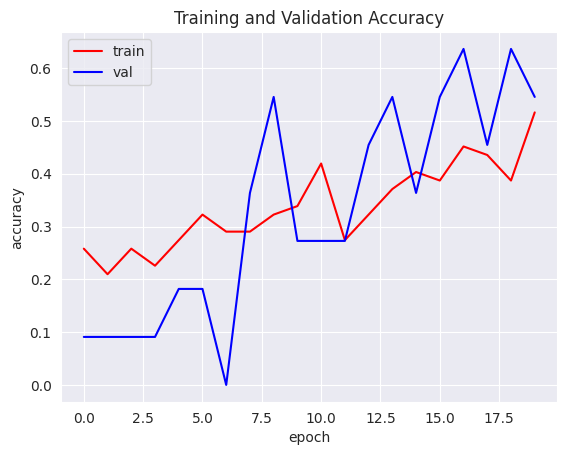

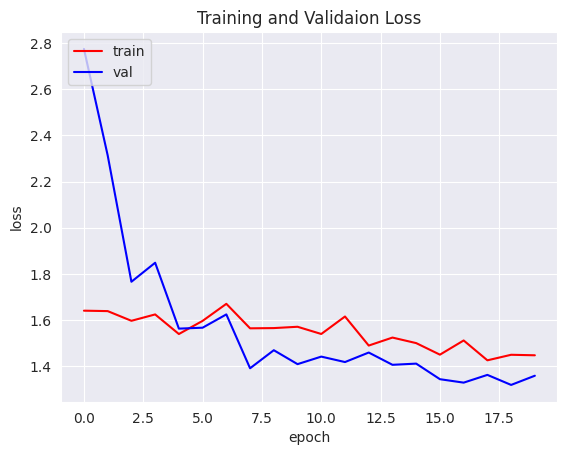

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'r')
plt.plot(epochs, val_acc, 'b')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(epochs, loss, 'r')
plt.plot(epochs, val_loss, 'b')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.title('Training and Validaion Loss')
plt.show()

In [ ]:
model_finetune = model_1

In [ ]:
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score
import numpy as np

y_true = validation_generator.classes
y_pred_probs = model_finetune.predict(validation_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

bal_acc = balanced_accuracy_score(y_true, y_pred)
qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

print("Balanced Accuracy:", bal_acc)
print("Quadratic Weighted Kappa:", qwk)


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
Balanced Accuracy: 0.7142857142857142
Quadratic Weighted Kappa: 0.5736434108527131


In [ ]:
base_model.trainable = True

fine_tune_at = len(base_model.layers) - 5 # mulai freeze dari awal sampai sebelum 20 terakhir
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Re-compile model
model_finetune.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history_finetune = model_finetune.fit(train_generator,
                             validation_data=validation_generator,
                             epochs=20)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 65s 16s/step - accuracy: 0.4314 - loss: 1.4372 - val_accuracy: 0.7273 - val_loss: 1.2075
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 62s 17s/step - accuracy: 0.4386 - loss: 1.3350 - val_accuracy: 0.8182 - val_loss: 0.6965
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 61s 15s/step - accuracy: 0.5202 - loss: 1.1672 - val_accuracy: 0.7273 - val_loss: 0.5535
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 62s 16s/step - accuracy: 0.6798 - loss: 1.1215 - val_accuracy: 0.7273 - val_loss: 0.5937
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 61s 16s/step - accuracy: 0.7967 - loss: 0.8677 - val_accuracy: 0.7273 - val_loss: 0.7316
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 82s 16s/step - accuracy: 0.6480 - loss: 0.9096 - val_accuracy: 0.7273 - val_loss: 0.6532
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 59s 15s/step - accuracy: 0.7422 - loss: 0.7232 - val_accuracy: 0.7273 - val_loss: 0.8221
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 63s 17s/step - accuracy: 0.8857 - loss: 0.5252 - val_accuracy: 0.7273 - val_loss: 0.6082


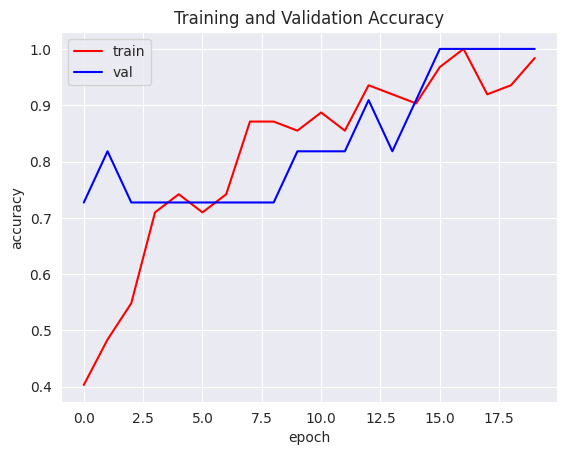

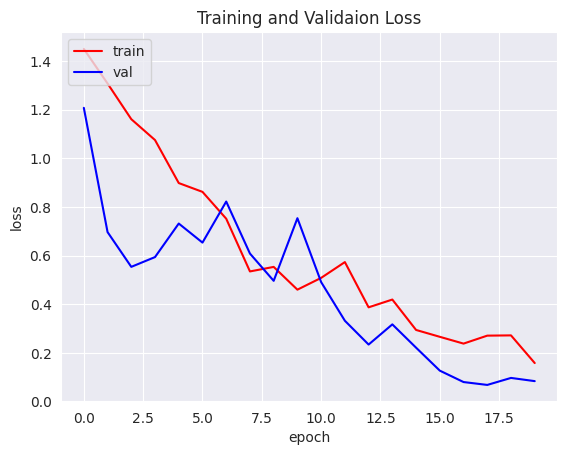

In [ ]:
acc = history_finetune.history['accuracy']
val_acc = history_finetune.history['val_accuracy']
loss = history_finetune.history['loss']
val_loss = history_finetune.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'r')
plt.plot(epochs, val_acc, 'b')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(epochs, loss, 'r')
plt.plot(epochs, val_loss, 'b')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.title('Training and Validaion Loss')
plt.show()

In [ ]:
y_true = validation_generator.classes
y_pred_probs = model_finetune.predict(validation_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

bal_acc = balanced_accuracy_score(y_true, y_pred)
qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

print("Balanced Accuracy:", bal_acc)
print("Quadratic Weighted Kappa:", qwk)

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
Balanced Accuracy: 1.0
Quadratic Weighted Kappa: 1.0


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


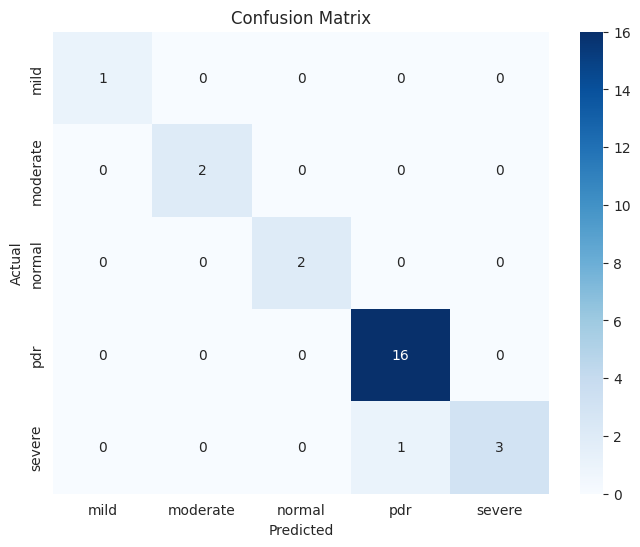

              precision    recall  f1-score   support

        mild     1.0000    1.0000    1.0000         1
    moderate     1.0000    1.0000    1.0000         2
      normal     1.0000    1.0000    1.0000         2
         pdr     0.9412    1.0000    0.9697        16
      severe     1.0000    0.7500    0.8571         4

    accuracy                         0.9600        25
   macro avg     0.9882    0.9500    0.9654        25
weighted avg     0.9624    0.9600    0.9577        25



In [ ]:
# Prediksi
pred_probs = model_finetune.predict(test_generator, verbose=0)
pred_classes = np.argmax(pred_probs, axis=1)

true_classes = test_generator.classes  # label asli (0-4)
class_labels = list(test_generator.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(true_classes, pred_classes)
df_cm = pd.DataFrame(cm, index=class_labels, columns=class_labels)

plt.figure(figsize=(8,6))
sns.heatmap(df_cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

print(classification_report(true_classes, pred_classes, target_names=class_labels, digits=4))

In [ ]:
model_finetune.save("dr_classification_model_mata_undaan.h5")

In [ ]:
import tensorflow as tf

# Load your trained model
model = tf.keras.models.load_model("dr_classification_model_mata_undaan.h5")

# Convert the model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the converted model
with open("dr_classification_model_mata_undaan.tflite", "wb") as f:
    f.write(tflite_model)

print("Model successfully converted and saved as dr_classification_model_mata_undaan.tflite")

Saved artifact at '/tmp/tmpn_w7j04j'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140140420005712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420005136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420004176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420004944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420003792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420003984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420003408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420003600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420003024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420003216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140140420002640

In [ ]:
# import tensorflow as tf
# import numpy as np
# from PIL import Image

# # Load model Keras
# model = tf.keras.models.load_model("dr_classification_model_fix.h5")

# Load gambar yang akan diprediksi
img = Image.open("/content/severe.png")
plt.imshow(img)
img = preprocess(img)
plt.imshow(img)

img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Prediksi kelas
pred = model_finetune.predict(img_array)
pred_class = np.argmax(pred, axis=1)[0]

# Mapping kelas {'Mild': 0, 'Moderate': 1, 'No_DR': 2, 'Proliferate_DR': 3, 'Severe': 4}
severity_mapping = {0:"Mild",1:"Moderate",2:"No_DR",3:"Proliferate_DR",4:"Severe"}
print("Prediksi kelas:", severity_mapping[pred_class])

FileNotFoundError: [Errno 2] No such file or directory: '/content/severe.png'

In [ ]:
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

In [ ]:
from PIL import Image

# Load TFLite model
interpreter = tf.lite.Interpreter(model_path="/content/dr_classification_model.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

img = Image.open("/content/0005cfc8afb6.jpg").resize((224, 224))  # sesuaikan dengan model
img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0) / 255.0

interpreter.set_tensor(input_details[0]['index'], img_array)

interpreter.invoke()

output_data = interpreter.get_tensor(output_details[0]['index'])
print("Output prediksi:", output_data)

# Prediksi kelas
predicted_class = np.argmax(output_data, axis=1)
print("Prediksi kelas:", predicted_class)


In [ ]:
from skimage.transform import rotate, AffineTransform, warp

def augment_image(img):
    transforms = [
        lambda x: np.clip(rotate(x, angle=random.uniform(-15,15), mode='edge'), 0, 255),
        lambda x: np.clip(np.flipud(x), 0, 255),
        lambda x: np.clip(np.fliplr(x), 0, 255),
        lambda x: np.clip(x*random.uniform(0.8,1.2), 0, 255)
    ]
    t = random.choice(transforms)
    return t(img).astype(np.uint8)

In [ ]:
def tta_predict(model, img, tta_transforms=1):
    preds = []
    for _ in range(tta_transforms):
        aug_img = augment_image(img)
        aug_img = np.expand_dims(aug_img/255.0, axis=0)
        pred = model.predict(aug_img)
        preds.append(pred)
    return np.mean(preds, axis=0)

# Predict on test set with TTA
y_true = []
y_pred = []

for i in range(len(test_generator)):
    img, label = test_generator[i]
    img = np.squeeze(img) * 255
    pred = tta_predict(model_1, img)
    y_true.append(np.argmax(label))
    y_pred.append(np.argmax(pred))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Evaluate with Balanced Accuracy and QWK
ba = balanced_accuracy_score(y_true, y_pred)
qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')

print("Balanced Accuracy (after TTA):", ba)
print("Quadratic Weighted Kappa (after TTA):", qwk)